# How early can you flag at-risk students, and who gets flagged?

An early-warning analysis on the **Open University Learning Analytics Dataset (OULAD)**: about 32,000 students, 22 course presentations, 10.6 million click records and every assessment result. Published by its original authors (Kuzilek, Hlosta, Zdrahal) under CC BY 4.0.

**Setup**
- **At risk** = final result Withdrawn or Fail.
- At each week *W*, predict using only what is known by then: demographics, clicks, active days, recent activity, assignments submitted, missed and late, average score.
- Only students **still enrolled at week W** are scored, so early dropouts don't inflate results.
- **Temporal split:** train on 2013 course presentations, test on 2014, like a college deploying last year's model this year.
- Advisors can't call everyone, so the key metric is **precision of the top 10% flagged**: of the students an advisor reaches, how many are truly at risk.

In [1]:
import pandas as pd, numpy as np, pyreadr
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score, brier_score_loss
import matplotlib.pyplot as plt
# Data: the .rda files from github.com/jakubkuzilek/oulad (data/ folder), or the CSVs from analyse.kmi.open.ac.uk
DATA_DIR = '/tmp/data/oulad/data/'

In [2]:
D=DATA_DIR
rd=lambda f: list(pyreadr.read_r(D+f+'.rda').values())[0]
stu=rd('student'); reg=rd('student_registration'); sa=rd('student_assessment'); asm=rd('assessment'); vle=rd('student_vle')
key=['code_module','code_presentation','id_student']
stu=stu.merge(reg,on=key)
stu['y']=stu.final_result.isin(['Withdrawn','Fail']).astype(int)
vle['week']=(vle.date//7).astype(int)
wk=vle.groupby(key+['week']).sum_click.sum().reset_index()
days=vle.groupby(key+['date']).size().reset_index()[key+['date']]
asm2=asm[asm.assessment_type!='Exam'].dropna(subset=['date'])
sa2=sa.merge(asm2,on='id_assessment')

sa, asm = sa2, asm2   # non-exam assessments with due dates
print(f'{len(stu):,} student-course records; {stu.y.mean():.0%} withdrew or failed')

32,593 student-course records; 53% withdrew or failed


In [3]:
key=['code_module','code_presentation','id_student']

demo_cols=['num_of_prev_attempts','studied_credits','date_registration']
cat=pd.get_dummies(stu[['highest_education','imd_band','age_band','gender','disability','code_module']].astype(str),dtype=float)
base=pd.concat([stu[key+['y','date_unregistration']+demo_cols].reset_index(drop=True),cat.reset_index(drop=True)],axis=1)
def feats(W):
    cut=7*W
    b=base[(base.date_unregistration.isna())|(base.date_unregistration>cut)].copy()
    w=wk[wk.week<W]
    f=w.groupby(key).sum_click.agg(clicks='sum').reset_index()
    f2=w[w.week>=W-2].groupby(key).sum_click.sum().rename('clicks_last2').reset_index()
    d=days[days.date<cut].groupby(key).size().rename('active_days').reset_index()
    pre=wk[wk.week<0].groupby(key).sum_click.sum().rename('preclicks').reset_index()
    due=asm[asm.date<cut]
    ndue=due.groupby(['code_module','code_presentation']).size().rename('n_due').reset_index()
    s=sa[(sa.date<cut)&(sa.date_submitted<cut)]
    sub=s.groupby(key).agg(n_sub=('id_assessment','count'),avg_score=('score',lambda x: pd.to_numeric(x,errors='coerce').mean()),late=('date_submitted',lambda x: 0)).reset_index()
    s=s.assign(late=(s.date_submitted>s.date).astype(int))
    late=s.groupby(key).late.sum().reset_index()
    for g in [f,f2,d,pre,sub.drop(columns='late'),late]:
        b=b.merge(g,on=key,how='left')
    b=b.merge(ndue,on=['code_module','code_presentation'],how='left')
    for c in ['clicks','clicks_last2','active_days','preclicks','n_sub','late','n_due']: b[c]=b[c].fillna(0)
    b['missed']=(b.n_due-b.n_sub).clip(lower=0)
    b['avg_score']=b.avg_score.fillna(-1)
    return b
beh=['clicks','clicks_last2','active_days','preclicks','n_sub','missed','late','avg_score','n_due']
demo=demo_cols+list(cat.columns)


## 1. How early does the signal appear?

In [4]:
rows=[]
for W in [0,2,4,6,8,10,12]:
    b=feats(W)
    tr=b[b.code_presentation.str.startswith('2013')]; te=b[b.code_presentation.str.startswith('2014')]
    for name,cols in [('demographics only',demo),('activity + assessments',demo+beh)]:
        if W==0 and name!='demographics only': cols=demo+['preclicks']
        m=HistGradientBoostingClassifier(max_iter=300,learning_rate=0.05,random_state=0).fit(tr[cols],tr.y)
        p=m.predict_proba(te[cols])[:,1]
        k=int(0.1*len(te)); top=np.argsort(-p)[:k]
        rows.append(dict(week=W,model=name,still_enrolled=len(te),at_risk_rate=te.y.mean(),auc=roc_auc_score(te.y,p),
                         precision_top10=te.y.values[top].mean()))
r=pd.DataFrame(rows); r.round(3)

,week,model,still_enrolled,at_risk_rate,auc,precision_top10
0,0,demographics only,17195,0.487,0.629,0.700
1,0,activity + assessments,17195,0.487,0.691,0.778
2,2,demographics only,16027,0.450,0.610,0.656
3,2,activity + assessments,16027,0.450,0.705,0.788
4,4,demographics only,15729,0.440,0.614,0.642
5,4,activity + assessments,15729,0.440,0.760,0.901
6,6,demographics only,15404,0.428,0.618,0.636
7,6,activity + assessments,15404,0.428,0.780,0.932
8,8,demographics only,15092,0.416,0.617,0.609
9,8,activity + assessments,15092,0.416,0.803,0.960


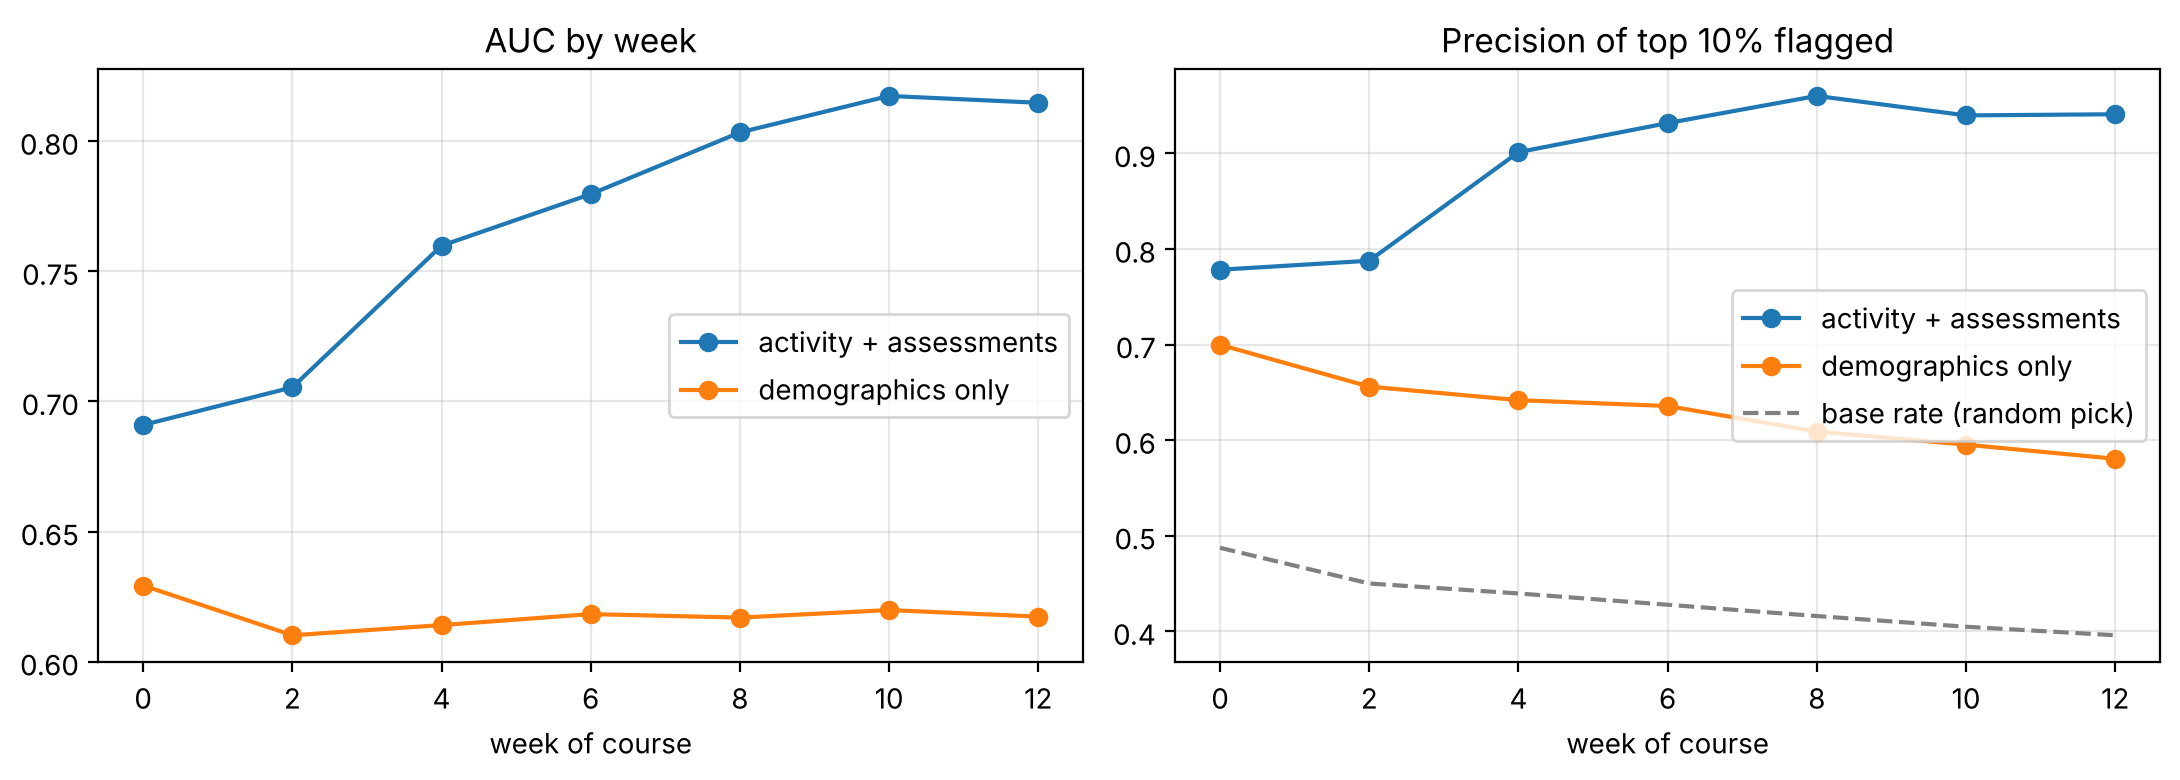

In [5]:
fig,ax=plt.subplots(1,2,figsize=(11,4))
for name,g in r.groupby('model'):
    ax[0].plot(g.week,g.auc,marker='o',label=name); ax[1].plot(g.week,g.precision_top10,marker='o',label=name)
baseline=r[r.model=='demographics only']
ax[1].plot(baseline.week,baseline.at_risk_rate,ls='--',c='gray',label='base rate (random pick)')
ax[0].set_title('AUC by week'); ax[1].set_title('Precision of top 10% flagged')
for a in ax: a.set_xlabel('week of course'); a.grid(alpha=.3)
ax[0].legend(loc='center right'); ax[1].legend(loc='center right')
plt.tight_layout(); plt.show()

**Takeaways**
- Demographics alone plateau around AUC 0.62. They can't see what the student is actually doing.
- By **week 4**, activity and assessment signals reach AUC 0.76, and **9 in 10 students in the top 10% are truly at risk** (versus about 44% by random pick).
- The biggest jump is weeks 2→4, right after the first assignments are due: a missed first assignment is one of the strongest early signals.

## 2. Who gets flagged? (week 4)

In [6]:
W=4; b=feats(W)
tr=b[b.code_presentation.str.startswith('2013')]; te=b[b.code_presentation.str.startswith('2014')].copy()
te=te.merge(stu[key+['imd_band']],on=key,how='left')
most=te.imd_band.astype(str).isin(['0-10%','10-20','10-20%']); least=te.imd_band.astype(str).isin(['80-90%','90-100%'])
out=[]
for name,cols in [('demographics only',demo),('activity + assessments, with demographics',demo+beh),
                  ('activity + assessments only',beh+['num_of_prev_attempts','studied_credits','date_registration'])]:
    m=HistGradientBoostingClassifier(max_iter=300,learning_rate=0.05,random_state=0).fit(tr[cols],tr.y)
    te['p']=m.predict_proba(te[cols])[:,1]; k=int(0.1*len(te)); te['flag']=te.p>=np.sort(te.p.values)[-k]
    out.append({'model':name,'AUC':roc_auc_score(te.y,te.p),'precision top 10%':te[te.flag].y.mean(),
        'flag rate, most deprived 20%':te[most].flag.mean(),'flag rate, least deprived 20%':te[least].flag.mean(),
        'actual at-risk rate, most deprived':te[most].y.mean(),'actual at-risk rate, least deprived':te[least].y.mean()})
pd.DataFrame(out).set_index('model').T.round(3)

model,demographics only,"activity + assessments, with demographics",activity + assessments only
AUC,0.614,0.760,0.739
precision top 10%,0.642,0.901,0.879
"flag rate, most deprived 20%",0.300,0.135,0.115
"flag rate, least deprived 20%",0.026,0.066,0.076
"actual at-risk rate, most deprived",0.521,0.521,0.521
"actual at-risk rate, least deprived",0.364,0.364,0.364


**Takeaways**
- A demographics-heavy model flags students from the most deprived areas at **about 11x** the rate of the least deprived, even though their actual at-risk rates differ by only about 1.4x. It flags *who students are*, not *what they're doing*.
- Behavior-based models narrow that gap a lot and are more precise for **both** groups.
- Removing demographic features entirely costs little (AUC 0.76 → 0.74, precision 0.90 → 0.88). That's a cheap trade for a model a university can defend to students and its review boards.

## 3. How much time does an early flag buy?

In [7]:
w=te[(te.flag)&(te.date_unregistration.notna())]
print(f'{len(w)} students flagged at week 4 later withdrew; median {np.median(w.date_unregistration-28):.0f} days between flag and withdrawal')

651 students flagged at week 4 later withdrew; median 53 days between flag and withdrawal


About **7 weeks** of lead time: enough for several advisor contacts before a student leaves.

## Caveats
- One UK distance-learning university; US campuses differ (residential, different LMS signals).
- "Precision of top 10%" assumes a fixed advisor capacity; the right cutoff depends on staffing.
- Deprivation band is the only equity variable checked here; a real deployment should audit more groups and track outcomes of the outreach itself.

By Jahangir Mammadli · mammadli.dev · Data: OULAD (Kuzilek, Hlosta & Zdrahal, 2017), CC BY 4.0